# Dự đoán thời lượng kỹ thuật sửa chữa thiết bị Apple

**Trạng thái: EXPERIMENTAL_DEMO — chỉ dùng dữ liệu tổng hợp — chưa kiểm chứng sản xuất — chưa tích hợp runtime.**

Notebook này là luồng final duy nhất: dữ liệu → EDA → bằng chứng feature → tiền xử lý →
chia thời gian → baseline → Random Forest / XGBoost / CatBoost → tuning → temporal CV →
khóa winner → final holdout → diagnostics → artifact → inference mẫu.

## 1. Bài toán hồi quy và target

Với $D=\{(x_i,y_i)\}_{i=1}^{n}$, mô hình học $\hat y_i=f(x_i)$ cho biến liên tục
`actual_technical_minutes`. Đây không phải ETA và không phải phân loại.

$$y=\frac{1}{60}\sum_{k:s_k\in\{INSPECTING,REPAIRING\}}
\max(0,\min(e_k,a_e)-\max(b_k,a_s))_{seconds}.$$

Mỗi khoảng trạng thái kỹ thuật $[b_k,e_k)$ được giao với assignment duy nhất
$[a_s,a_e)$. Queue, chờ duyệt, chờ linh kiện, break, transfer gap và chờ bàn giao bị loại.

## 2. Sample grain, thời điểm dự đoán và bảo hành

Một mẫu là ticket hoàn tất có đúng một RepairItem APPROVED, một catalog cụ thể,
một assignment đã kết thúc, không transfer được chấp nhận, history đầy đủ và target dương.
Prediction timestamp là lúc assignment đầu tiên bắt đầu sau khi phương án đã biết.

`technical_action` chỉ có REPAIR/REPLACEMENT. `is_warranty` là ngữ cảnh nhị phân;
không có action WARRANTY và không có hệ số thời lượng bảo hành ẩn.

In [1]:
%matplotlib inline
from pathlib import Path
import json, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, catboost

ML_ROOT = Path('ml') if Path('ml').exists() else Path.cwd()
sys.path.insert(0, str((ML_ROOT / 'src').resolve()))
from repair_duration_ml.config import *
from repair_duration_ml.data import load_dataset, temporal_holdout_split, feature_target
from repair_duration_ml.evaluation import cold_start_examples, development_numeric_correlations
from repair_duration_ml.features import FEATURE_ABLATION_STAGES, FEATURE_EVIDENCE
from repair_duration_ml.models import build_model_specs
from repair_duration_ml.training import run_competition, sha256_file

DATA_PATH = ML_ROOT / 'data' / 'synthetic_repair_duration.csv'
ARTIFACT_DIR = ML_ROOT / 'models' / 'experimental'
frame = load_dataset(DATA_PATH)
{
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'xgboost': xgboost.__version__, 'catboost': catboost.__version__},
    'seed': SEED, 'sha256': sha256_file(DATA_PATH), 'shape': frame.shape,
    'duplicates': int(frame.duplicated().sum()),
    'missing': frame.isna().sum()[frame.isna().sum().gt(0)].to_dict(),
}

{'versions': {'python': '3.13.6',
  'sklearn': '1.8.0',
  'xgboost': '3.2.0',
  'catboost': '1.2.8'},
 'seed': 20261007,
 'sha256': 'a0d7bfd0ace36c7fb940a62203dcd8ef75875391455f65b11e52df66e3e43c2f',
 'shape': (5000, 24),
 'duplicates': 0,
 'missing': {'technician_average_duration_before': 24,
  'technician_historical_efficiency_before': 24,
  'technician_issue_average_duration_before': 149,
  'technician_issue_efficiency_before': 149,
  'technician_catalog_average_duration_before': 449,
  'technician_catalog_efficiency_before': 449}}

## 3. Data dictionary và kiểm tra quan hệ

Các trường lịch sử đều kết thúc bằng `_before` để thể hiện đúng thời điểm. Count = 0
khi chưa có lịch sử; average/efficiency = NaN. Danh mục tổng hợp chỉ sinh các tổ hợp
device type, model, issue, action và catalog đã khai báo; latent capability, specialty,
complexity, noise và outlier không được xuất thành feature.

In [2]:
data_dictionary = pd.DataFrame([
    {'feature': c, 'type': 'numeric' if c in NUMERIC_FEATURES else 'categorical',
     'available_at_prediction': True, 'leakage_safe': True}
    for c in FINAL_FEATURE_COLUMNS
])
display(data_dictionary)
display(frame.head(3))
display(frame.dtypes.rename('dtype').to_frame())
display(frame[TARGET].describe(percentiles=[.5,.9,.95]).round(3))

,feature,type,available_at_prediction,leakage_safe
0,device_type,categorical,True,True
1,device_model,categorical,True,True
2,service_issue,categorical,True,True
3,technical_action,categorical,True,True
4,is_warranty,numeric,True,True
5,catalog_service,categorical,True,True
6,standard_duration_minutes,numeric,True,True
7,technician_id,categorical,True,True
8,branch_id,categorical,True,True
9,prediction_month,categorical,True,True


,sample_id,prediction_timestamp,completed_at,device_type,device_model,service_issue,technical_action,is_warranty,catalog_service,standard_duration_minutes,...,technician_jobs_completed_before,technician_average_duration_before,technician_historical_efficiency_before,technician_issue_jobs_before,technician_issue_average_duration_before,technician_issue_efficiency_before,technician_catalog_jobs_before,technician_catalog_average_duration_before,technician_catalog_efficiency_before,actual_technical_minutes
0,SYN_RD_FINAL_000001,2025-01-02 11:49:00,2025-01-02 13:30:00,iPhone,iPhone 13,Cổng sạc,REPAIR,1,Sửa cổng sạc iPhone 13,80,...,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,86
1,SYN_RD_FINAL_000002,2025-01-02 12:22:00,2025-01-02 15:17:00,AirPods,AirPods 3,Pin tai nghe,REPLACEMENT,0,Thay pin tai nghe AirPods 3,70,...,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,124
2,SYN_RD_FINAL_000003,2025-01-02 13:02:00,2025-01-02 19:48:00,iPhone,iPhone 16 Pro,Mainboard,REPAIR,1,Sửa mainboard iPhone 16 Pro,220,...,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,396


,dtype
sample_id,str
prediction_timestamp,datetime64[us]
completed_at,datetime64[us]
device_type,str
device_model,str
service_issue,str
technical_action,str
is_warranty,int64
catalog_service,str
standard_duration_minutes,int64


count    5000.000
mean      148.541
std        84.017
min        30.000
50%       128.000
90%       258.000
95%       322.000
max       600.000
Name: actual_technical_minutes, dtype: float64

## 4. Chia thời gian trước mọi phân tích có target

85% đầu là development; 15% cuối là holdout nguyên vẹn. Correlation, EDA, ablation,
tuning và chọn winner chỉ dùng development. Holdout không được dùng để sửa feature,
hyperparameter hay đổi winner.

In [3]:
split = temporal_holdout_split(frame)
X_dev, y_dev = feature_target(split.development)
X_test, y_test = feature_target(split.test)
pd.DataFrame([
    {'partition':'development','rows':len(split.development),
     'start':split.development[TIME_COLUMN].min(),'end':split.development[TIME_COLUMN].max()},
    {'partition':'untouched_holdout','rows':len(split.test),
     'start':split.test[TIME_COLUMN].min(),'end':split.test[TIME_COLUMN].max()},
])

,partition,rows,start,end
0,development,4250,2025-01-02 11:49:00,2026-06-30 08:17:00
1,untouched_holdout,750,2026-06-30 08:29:00,2026-09-30 17:34:00


## 5. EDA chỉ trên development

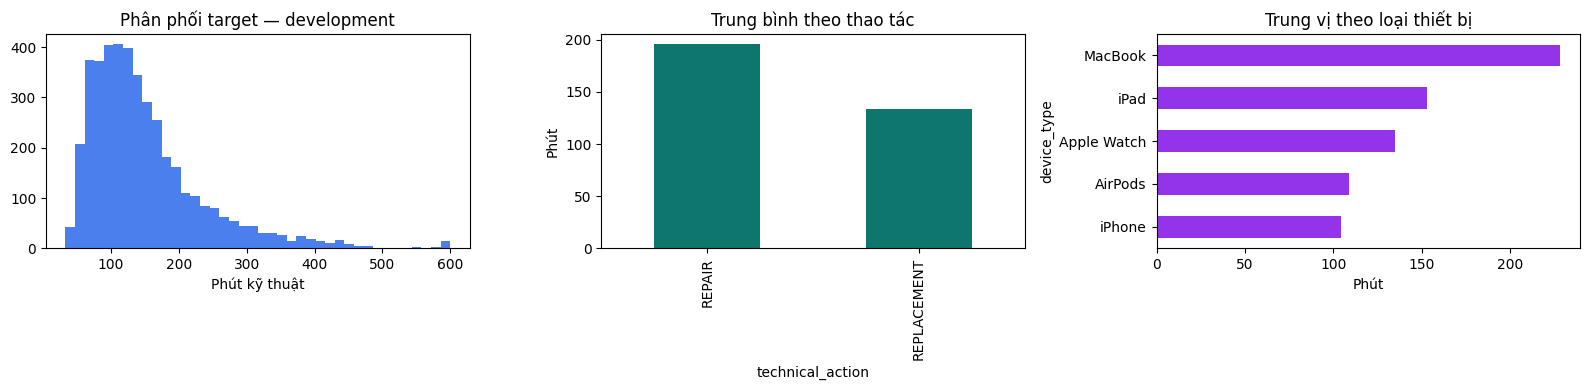

In [4]:
eda = split.development
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(eda[TARGET], bins=40, color='#2563eb', alpha=.82)
axes[0].set(title='Phân phối target — development', xlabel='Phút kỹ thuật')
eda.groupby('technical_action', observed=True)[TARGET].mean().plot.bar(ax=axes[1], color='#0f766e')
axes[1].set(title='Trung bình theo thao tác', ylabel='Phút')
eda.groupby('device_type', observed=True)[TARGET].median().sort_values().plot.barh(ax=axes[2], color='#9333ea')
axes[2].set(title='Trung vị theo loại thiết bị', xlabel='Phút')
plt.tight_layout(); plt.show()

## 6. Bằng chứng correlation

Pearson $r_{XY}=\frac{\operatorname{cov}(X,Y)}{\sigma_X\sigma_Y}$ chỉ mô tả liên hệ
tuyến tính giữa các biến số trên development. Correlation không tự động quyết định giữ/bỏ
feature và không phải lý do biến category thành số nguyên tùy ý.

,correlation_with_target
standard_duration_minutes,0.810161
technician_catalog_average_duration_before,0.796642
technician_issue_average_duration_before,0.722445
technician_issue_efficiency_before,0.322908
technician_catalog_efficiency_before,0.284910
technician_catalog_jobs_before,-0.155910
technician_issue_jobs_before,-0.109494
technician_historical_efficiency_before,0.109489
technician_average_duration_before,0.086625
technician_jobs_completed_before,0.041142


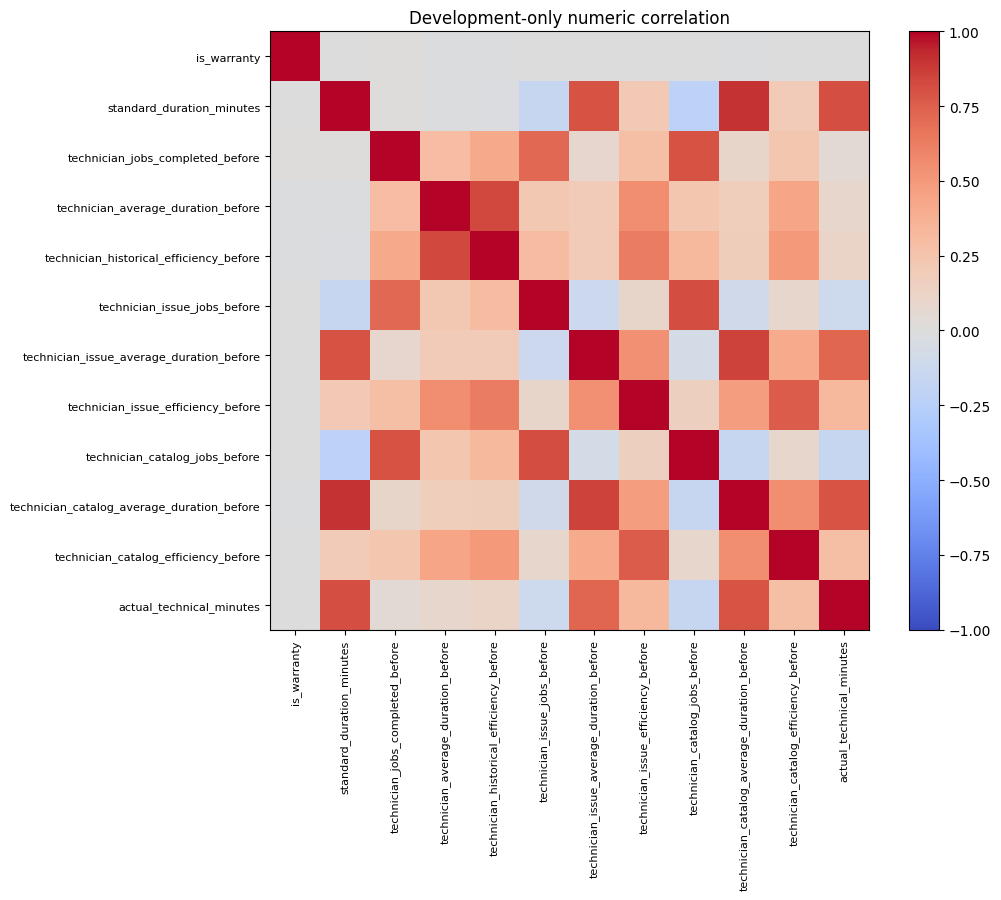

In [5]:
corr_matrix, target_corr = development_numeric_correlations(split.development)
display(target_corr.rename('correlation_with_target').to_frame())
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.index, fontsize=8)
fig.colorbar(image, ax=ax); ax.set_title('Development-only numeric correlation')
plt.tight_layout(); plt.show()

## 7. Bốn tầng bằng chứng feature

Mỗi nhóm phải có ý nghĩa nghiệp vụ, tồn tại tại prediction time, an toàn leakage và có
đóng góp dự báo trên development. Ablation dùng một XGBoost bảo thủ cố định và cùng bốn
fold; không tune theo holdout.

In [6]:
pd.DataFrame(FEATURE_EVIDENCE).T

,business_meaning,availability,leakage_safety
base_job,"Known device, issue, approved action, catalog ...",Available when the first assignment begins aft...,"No completion, feedback, future status or gene..."
technician_overall,Technician identity plus completed-job history.,Computed only from jobs completed before predi...,Strict completed_at < prediction_timestamp; un...
technician_issue,Prior experience of the technician on the same...,Derived from earlier completed matching jobs.,Strict as-of boundary; zero count and missing ...
technician_catalog,Prior experience on the exact catalog service.,Derived from earlier completed matching jobs.,Strict as-of boundary; no full-data aggregatio...


## 8. Tiền xử lý và missing value

- RF/XGB: median numeric được học riêng trong training fold; category dùng one-hot và
  `handle_unknown='ignore'`.
- CatBoost: category native và numeric NaN native.
- Không fit imputer/encoder trên toàn bộ dữ liệu; không dùng StandardScaler vì mô hình cây.

Median trong fold là $\tilde x_j=\operatorname{median}\{x_{ij}:i\in train\}$.

## 9. Baseline và metric

Mean baseline: $\hat y=\bar y_{train}$ trong từng fold. Business baseline:
$\hat y=standard\_duration\_minutes$.

$$MAE=\frac1n\sum|y_i-\hat y_i|,\quad MSE=\frac1n\sum(y_i-\hat y_i)^2,$$
$$RMSE=\sqrt{MSE},\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

$P90AE=Q_{0.90}(|y-\hat y|)$ và
$Within_t=100n^{-1}\sum\mathbf1(|y_i-\hat y_i|\le t)$ với $t\in\{15,30,45\}$.
R² không phải accuracy.

## 10. Random Forest Regressor

$$\hat y_{RF}(x)=\frac1B\sum_{b=1}^{B}T_b(x).$$

Bootstrap, lấy mẫu feature ngẫu nhiên và trung bình nhiều cây giúp giảm variance. Search:
`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`.

## 11. XGBoost Regressor

$$Obj^{(t)}\approx\sum_i[g_if_t(x_i)+\tfrac12h_if_t(x_i)^2]+\Omega(f_t),$$
$$g_i=\partial_{\hat y}l,\ h_i=\partial^2_{\hat y}l,\
\Omega(f)=\gamma T+\tfrac12\lambda\lVert w\rVert^2.$$

Objective là `reg:squarederror` để có gradient/Hessian bậc hai; đánh giá và chọn model
vẫn theo MAE. Search learning rate, depth, child weight, sampling và regularization.

## 12. CatBoost Regressor

CatBoost xử lý category native bằng ordered statistics. Trực giác rút gọn:
$$TS_i=\frac{\sum_{\sigma(j)<\sigma(i)}1[x_j=x_i]y_j+aP}
{\sum_{\sigma(j)<\sigma(i)}1[x_j=x_i]+a}.$$

Thứ tự permutation tránh dùng target của chính hàng đang encode. Loss train là RMSE,
eval/model selection là MAE. Search iterations, learning rate, depth, L2 và random strength.

## 13. Full temporal experiment

Ba candidate dùng đúng cùng `TimeSeriesSplit(4)`, 12 cấu hình ngẫu nhiên có seed cố định
cho mỗi model và scoring `neg_mean_absolute_error`. Cell này thực thi toàn bộ ablation,
tuning, CV, khóa winner rồi mới đánh giá holdout.

In [7]:
result = run_competition(
    DATA_PATH, output_dir=None, cv_splits=4, test_fraction=.15,
    search_iterations=12, smoke=False,
)
result.feature_ablation.round(4)

,stage,feature_count,cv_mae_mean,cv_mae_std,cv_rmse,cv_r2,cv_p90_absolute_error,delta_mae_vs_previous
0,BASE_JOB,10,35.6964,1.1705,50.1265,0.6442,72.8750,NaN
1,PLUS_TECHNICIAN_OVERALL_HISTORY,14,34.4743,2.1033,49.6325,0.6511,72.8565,-1.2221
2,PLUS_TECHNICIAN_ISSUE,17,34.0905,2.1723,49.0490,0.6594,71.1069,-0.3838
3,PLUS_TECHNICIAN_CATALOG,20,33.7995,1.9688,48.5519,0.6664,68.1803,-0.2910


## 14. Feature freeze sau ablation

In [8]:
display(result.feature_ablation.round(4))
print('FINAL_FEATURE_COLUMNS =')
print(FINAL_FEATURE_COLUMNS)

,stage,feature_count,cv_mae_mean,cv_mae_std,cv_rmse,cv_r2,cv_p90_absolute_error,delta_mae_vs_previous
0,BASE_JOB,10,35.6964,1.1705,50.1265,0.6442,72.8750,NaN
1,PLUS_TECHNICIAN_OVERALL_HISTORY,14,34.4743,2.1033,49.6325,0.6511,72.8565,-1.2221
2,PLUS_TECHNICIAN_ISSUE,17,34.0905,2.1723,49.0490,0.6594,71.1069,-0.3838
3,PLUS_TECHNICIAN_CATALOG,20,33.7995,1.9688,48.5519,0.6664,68.1803,-0.2910


FINAL_FEATURE_COLUMNS =
['device_type', 'device_model', 'service_issue', 'technical_action', 'is_warranty', 'catalog_service', 'standard_duration_minutes', 'technician_id', 'branch_id', 'prediction_month', 'prediction_weekday', 'technician_jobs_completed_before', 'technician_average_duration_before', 'technician_historical_efficiency_before', 'technician_issue_jobs_before', 'technician_issue_average_duration_before', 'technician_issue_efficiency_before', 'technician_catalog_jobs_before', 'technician_catalog_average_duration_before', 'technician_catalog_efficiency_before']


## 15. Search spaces và best hyperparameters

In [9]:
display(pd.DataFrame([
    {'model': name, 'search_space': result.search_spaces[name],
     'best_parameters': result.best_parameters[name],
     'preprocessing': result.preprocessing[name]}
    for name in MODEL_NAMES
]))

,model,search_space,best_parameters,preprocessing
0,RandomForestRegressor,"{'model__n_estimators': [160, 240, 320], 'mode...","{'model__n_estimators': 160, 'model__min_sampl...",Training-fold median numeric imputation plus s...
1,XGBRegressor,"{'model__n_estimators': [160, 240, 340], 'mode...","{'model__subsample': 0.9, 'model__reg_lambda':...",Training-fold median numeric imputation plus s...
2,CatBoostRegressor,"{'iterations': [160, 240, 320], 'learning_rate...","{'random_strength': 0.4, 'learning_rate': 0.02...",Native categorical handling and ordered statis...


## 16. Development temporal-CV và khóa winner

In [10]:
cv_columns = ['model','cv_mae_mean','cv_mae_std','cv_mse','cv_rmse','cv_r2',
              'cv_p90_absolute_error','cv_within_15_percent',
              'cv_within_30_percent','cv_within_45_percent','search_seconds']
display(result.cv_table[cv_columns].round(3))
{'locked_winner': result.winner_name, 'reason': result.winner_reason}

,model,cv_mae_mean,cv_mae_std,cv_mse,cv_rmse,cv_r2,cv_p90_absolute_error,cv_within_15_percent,cv_within_30_percent,cv_within_45_percent,search_seconds
0,CatBoostRegressor,32.744,2.038,2279.807,47.710,0.678,66.587,33.765,59.324,77.382,733.265
1,XGBRegressor,33.117,2.663,2310.669,47.980,0.674,68.240,32.471,58.941,76.412,20.518
2,RandomForestRegressor,33.586,2.519,2349.462,48.421,0.668,70.719,32.382,58.412,76.206,353.928
3,StandardDurationBaseline,39.600,1.941,3795.003,61.580,0.463,92.550,36.618,57.324,71.324,NaN
4,MeanBaseline,63.068,2.214,7128.655,84.421,-0.009,110.652,14.324,28.500,42.882,NaN


{'locked_winner': 'CatBoostRegressor',
 'reason': 'CatBoostRegressor had the lowest development temporal-CV MAE (32.744 minutes); the untouched test set was not consulted.'}

## 17. Final holdout

Winner đã khóa bằng CV trước cell này. Bảng có cả ba model để audit, nhưng không model nào
được đổi theo test. Đây là lần đọc final holdout duy nhất trong pipeline.

In [11]:
test_columns = ['model','mae','mse','rmse','r2','p90_absolute_error',
                'within_15_percent','within_30_percent','within_45_percent',
                'fit_seconds','predict_seconds']
result.test_table[test_columns].round(3)

,model,mae,mse,rmse,r2,p90_absolute_error,within_15_percent,within_30_percent,within_45_percent,fit_seconds,predict_seconds
0,CatBoostRegressor,29.494,1809.885,42.543,0.716,63.184,37.067,66.000,81.333,17.732,0.008
1,XGBRegressor,29.660,1821.606,42.680,0.715,64.357,36.400,64.533,80.933,0.191,0.022
2,RandomForestRegressor,30.349,1875.439,43.306,0.706,62.998,35.867,63.600,81.067,9.650,0.040
3,StandardDurationBaseline,37.051,3179.405,56.386,0.502,85.200,35.200,60.533,75.067,0.000,0.000
4,MeanBaseline,60.882,6509.112,80.679,-0.020,106.781,15.867,28.933,42.933,0.000,0.000


## 18. Residual diagnostics

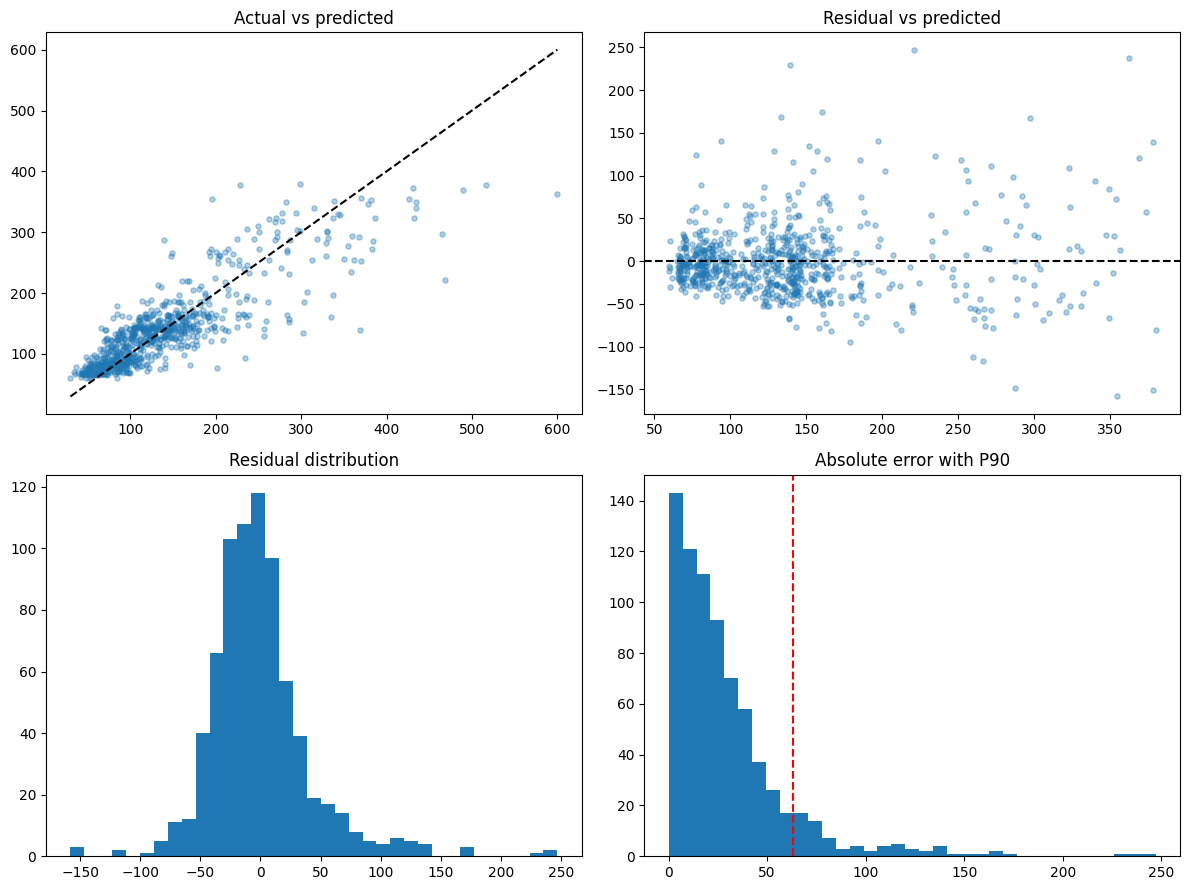

count    750.000
mean      -0.762
std       42.564
min     -158.235
25%      -25.324
50%       -5.497
75%       15.194
max      247.197
dtype: float64

In [12]:
residual = y_test.to_numpy() - result.test_predictions
absolute_error = np.abs(residual)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0,0].scatter(y_test, result.test_predictions, alpha=.35, s=14)
lo=min(y_test.min(),result.test_predictions.min()); hi=max(y_test.max(),result.test_predictions.max())
axes[0,0].plot([lo,hi],[lo,hi],'k--'); axes[0,0].set(title='Actual vs predicted')
axes[0,1].scatter(result.test_predictions,residual,alpha=.35,s=14)
axes[0,1].axhline(0,color='k',ls='--'); axes[0,1].set(title='Residual vs predicted')
axes[1,0].hist(residual,bins=35); axes[1,0].set(title='Residual distribution')
axes[1,1].hist(absolute_error,bins=35); axes[1,1].axvline(np.percentile(absolute_error,90),color='red',ls='--')
axes[1,1].set(title='Absolute error with P90')
plt.tight_layout(); plt.show()
pd.Series(residual).describe().round(3)

## 19. Permutation importance — diễn giải final

Giá trị là mức MAE tăng khi hoán vị một feature. Đây là association với dự báo, không phải
quan hệ nhân quả. Vì được tính trên holdout, bảng chỉ diễn giải winner; không quay lại bỏ
feature hoặc đổi model.

In [13]:
pd.DataFrame(result.feature_importances).round(4)

,feature,importance_mean_mae_increase,importance_std
0,standard_duration_minutes,30.3921,1.0223
1,technician_catalog_average_duration_before,0.9764,0.2082
2,technician_issue_efficiency_before,0.8148,0.2236
3,technical_action,0.5314,0.2410
4,device_type,0.2812,0.0553
5,branch_id,0.2432,0.0725
6,technician_issue_average_duration_before,0.2036,0.0396
7,technician_historical_efficiency_before,0.2020,0.0891
8,technician_id,0.1915,0.0714
9,catalog_service,0.1809,0.0395


## 20. Sai số theo subgroup

In [14]:
for group_name, rows in result.subgroup_metrics.items():
    print()
    print(group_name)
    display(pd.DataFrame(rows).round(3))


technician_id


,group,sample_count,mae,rmse
0,TECH_04,73,33.924,50.681
1,TECH_05,76,31.877,47.403
2,TECH_07,80,31.790,42.968
3,TECH_02,53,31.451,45.861
4,TECH_08,58,29.508,47.293
5,TECH_06,44,29.284,39.639
6,TECH_10,79,28.952,38.421
7,TECH_03,46,28.575,40.932
8,TECH_12,54,28.445,40.696
9,TECH_09,50,26.411,44.161



device_type


,group,sample_count,mae,rmse
0,MacBook,94,50.096,64.258
1,iPad,108,33.547,46.449
2,Apple Watch,62,27.079,34.758
3,iPhone,388,25.404,37.813
4,AirPods,98,22.983,32.980



service_issue


,group,sample_count,mae,rmse
0,Mainboard,56,66.574,85.142
1,Bàn phím,21,53.789,63.212
2,Chống ồn,12,39.574,58.328
3,Màn hình,204,31.864,42.756
4,Sạc không dây,12,29.480,43.020
5,Âm thanh,18,25.525,36.114
6,Cổng sạc,55,23.674,35.619
7,Pin,287,22.611,30.774
8,Camera,22,22.117,36.042
9,Digital Crown,11,21.066,26.796



technical_action


,group,sample_count,mae,rmse
0,REPAIR,196,39.940,57.686
1,REPLACEMENT,554,25.798,35.678



is_warranty


,group,sample_count,mae,rmse
0,0,657,29.706,42.825
1,1,93,27.991,40.495


## 21. Năm tình huống cold-start

In [15]:
pd.Series(result.cold_start_predictions, name='predicted_technical_minutes')

known_history                   212.455471
new_technician                  268.832108
overall_but_no_issue_history    237.586866
issue_but_no_catalog_history    223.900424
unseen_categories               265.644940
Name: predicted_technical_minutes, dtype: float64

## 22. Artifact đã lưu và inference mẫu

In [16]:
metadata = json.loads((ARTIFACT_DIR / 'metadata.json').read_text(encoding='utf-8'))
assert metadata['model_status'] == 'EXPERIMENTAL_DEMO'
assert metadata['synthetic_data'] and not metadata['production_validated'] and not metadata['runtime_integrated']
if metadata['model_file'].endswith('.cbm'):
    from catboost import CatBoostRegressor
    reloaded = CatBoostRegressor()
    reloaded.load_model(ARTIFACT_DIR / metadata['model_file'])
else:
    import joblib
    reloaded = joblib.load(ARTIFACT_DIR / metadata['model_file'])
example = cold_start_examples(X_dev).loc[['new_technician']]
{'model': metadata['winner_name'],
 'prediction_minutes': float(reloaded.predict(example)[0]),
 'finite': bool(np.isfinite(reloaded.predict(example)[0]))}

{'model': 'CatBoostRegressor',
 'prediction_minutes': 268.8321076905546,
 'finite': True}

## 23. Kết luận và giới hạn

- Kết quả chỉ chứng minh pipeline trên dữ liệu tổng hợp, không chứng minh chất lượng thực tế.
- Multi-item, transfer và history thiếu bị loại; production interruptions chưa được trừ.
- Subgroup nhỏ phải đọc cùng sample count; importance không phải causality.
- Không có classifier hài lòng, API inference, Spring/ETA/UI, ghi DB hay deployment.

**Các bước kế tiếp, chưa triển khai:** MySQL real extractor → runtime feature builder →
inference API → Spring Boot integration → `ml_predictions` → ETA → React UI → E2E test →
Docker/deployment.